In [3]:
from Bio import Entrez
import pandas as pd

# 1. Authenticate with NCBI
Entrez.email = "your.email@example.com" # Note: Insert your email here to comply with NCBI API guidelines

def fetch_pubmed_abstracts(query, max_results=50):
    print(f"Searching PubMed for: {query}...")
    
    # Step 1: ESearch - Get a list of PubMed IDs (PMIDs)
    search_handle = Entrez.esearch(db="pubmed", term=query, retmax=max_results)
    search_results = Entrez.read(search_handle)
    search_handle.close()
    
    pmid_list = search_results["IdList"]
    print(f"Found {len(pmid_list)} papers. Downloading abstracts...")

    # Step 2: EFetch - Download the actual text for those PMIDs
    fetch_handle = Entrez.efetch(db="pubmed", id=",".join(pmid_list), retmode="xml")
    articles = Entrez.read(fetch_handle)
    fetch_handle.close()

    # Step 3: Extract the titles and abstracts into a list
    data = []
    for article in articles['PubmedArticle']:
        medline = article['MedlineCitation']
        article_data = medline['Article']
        
        title = article_data.get('ArticleTitle', 'No Title')
        
        # Check if the paper actually has an abstract
        abstract_text = ""
        if 'Abstract' in article_data:
            abstract_parts = article_data['Abstract'].get('AbstractText', [])
            abstract_text = " ".join(str(part) for part in abstract_parts)
            
        # Only keep it if the abstract isn't blank
        if abstract_text: 
            data.append({
                "PMID": medline['PMID'],
                "Title": title,
                "Original_Abstract": abstract_text
            })
            
    # Convert the list into a clean Pandas table (DataFrame)
    return pd.DataFrame(data)

# Run the function to fetch 50 papers on insulin signaling
df = fetch_pubmed_abstracts("insulin signaling pathway", max_results=50)

# Display the first 5 rows to make sure it worked
df.head()

Searching PubMed for: insulin signaling pathway...
Found 50 papers. Downloading abstracts...


,PMID,Title,Original_Abstract
0,43045134,[Effects of Tongqiao Huoxue Decoction on cogni...,To investigate the effects of Tongqiao Huoxue ...
1,43045132,[Jatrorrhizine alleviates hepatic endoplasmic ...,This study aimed to explore the mechanism by w...
2,43044975,From Obesity to Cancer Cachexia: PI3K/AKT/MTOR...,The PI3K/AKT/MTOR signaling pathway is overact...
3,43044866,Bergapten ameliorates type 2 diabetes mellitus...,"Bergapten (BP), derived from traditional Chine..."
4,43044181,Hyperinsulinemia contributes to regulatory T-c...,"We examined relationships among obesity, hyper..."


In [4]:
!pip install textstat

In [5]:
import textstat

# 1. Define a function to calculate the readability scores
def get_complexity(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return pd.Series([None, None])
        
    # Flesch Reading Ease (0-100 scale: lower = harder to read)
    reading_ease = textstat.flesch_reading_ease(text)
    
    # Flesch-Kincaid Grade Level (Estimates years of education required to understand it)
    grade_level = textstat.flesch_kincaid_grade(text)
    
    return pd.Series([reading_ease, grade_level])

print("Calculating complexity scores...")

# 2. Apply the math to your abstract column
df[['Original_Reading_Ease', 'Original_Grade_Level']] = df['Original_Abstract'].apply(get_complexity)

# 3. Print out the average grade level of the whole dataset
average_grade = df['Original_Grade_Level'].mean()
print(f"\nAverage Grade Level required for original abstracts: {average_grade:.1f}")

# 4. Display the first 5 rows to see the new score columns
df[['PMID', 'Original_Reading_Ease', 'Original_Grade_Level']].head()



!pip install google-generativeai tqdm



from google import genai
import time
from tqdm import tqdm

# 1. Connect with the SDK
client = genai.Client(api_key="YOUR_API_KEY_HERE")

def get_ai_summary(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return "No text"
        
    prompt = f"Summarize the following molecular biology abstract into one simple, easy-to-read paragraph. Remove complex jargon. Abstract: {text}"
    
    for attempt in range(3):
        try:
            # Switch to the high-throughput 3.5 model
            response = client.models.generate_content(
                model='gemini-3.5-flash',
                contents=prompt
            )
            return response.text.strip()
        except Exception as e:
            error_str = str(e)
            if "503" in error_str or "429" in error_str:
                time.sleep(15) # Extended 15-second pause during overloads
                continue
            else:
                return f"API Error: {e}"
                
    return "API Error: Server repeatedly unavailable"

print("Sending abstracts to the AI (Bypassing server load)...")

ai_summaries = []
for abstract in tqdm(df['Original_Abstract']):
    summary = get_ai_summary(abstract)
    ai_summaries.append(summary)
    
    # Increased base pause to 4.5 seconds
    time.sleep(4.5) 

df['AI_Summary'] = ai_summaries
df[['PMID', 'AI_Summary']].head()


Calculating complexity scores...

Average Grade Level required for original abstracts: 19.8
Sending abstracts to the AI (Bypassing server load)...


100%|████████████████████████████████████████████████████████████████████████████████| 50/50 [1:12:35<00:00, 87.11s/it]


,PMID,AI_Summary
0,43045134,This study investigated whether a traditional ...
1,43045132,This study investigated how a natural plant co...
2,43044975,A large review of 139 studies examined how bod...
3,43044866,"Bergapten, a natural compound found in traditi..."
4,43044181,This study found that high insulin levels asso...


In [6]:
import textstat
import pandas as pd

# 1. Define the scoring function (safeguarded against any blank rows)
def get_complexity(text):
    if not isinstance(text, str) or len(text.strip()) == 0 or "API Error" in text:
        return pd.Series([None, None])
        
    reading_ease = textstat.flesch_reading_ease(text)
    grade_level = textstat.flesch_kincaid_grade(text)
    
    return pd.Series([reading_ease, grade_level])

print("Calculating AI readability scores...")

# 2. Score the AI summaries
df[['AI_Reading_Ease', 'AI_Grade_Level']] = df['AI_Summary'].apply(get_complexity)

# 3. Calculate the mathematical difference
original_average = df['Original_Grade_Level'].mean()
ai_average = df['AI_Grade_Level'].mean()
grade_drop = original_average - ai_average

print(f"\nBaseline (Original Abstracts): {original_average:.1f} Grade Level")
print(f"Simplified (AI Summaries):   {ai_average:.1f} Grade Level")
print(f"--> The AI dropped the reading difficulty by {grade_drop:.1f} grade levels!")

# 4. Display a clean side-by-side comparison table
df[['PMID', 'Original_Grade_Level', 'AI_Grade_Level']].head()



Calculating AI readability scores...

Baseline (Original Abstracts): 19.8 Grade Level
Simplified (AI Summaries):   15.3 Grade Level
--> The AI dropped the reading difficulty by 4.5 grade levels!


,PMID,Original_Grade_Level,AI_Grade_Level
0,43045134,19.500558,15.030435
1,43045132,20.762588,15.554919
2,43044975,18.300992,17.491677
3,43044866,17.941203,14.608189
4,43044181,19.808409,15.638469


Data saved successfully as 'insulin_readability_gap.csv'


C:\Users\rudra\AppData\Local\Temp\ipykernel_1256\1871282175.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Text_Type', y='Grade_Level', data=plot_data, palette=['#ff9999', '#66b3ff'])


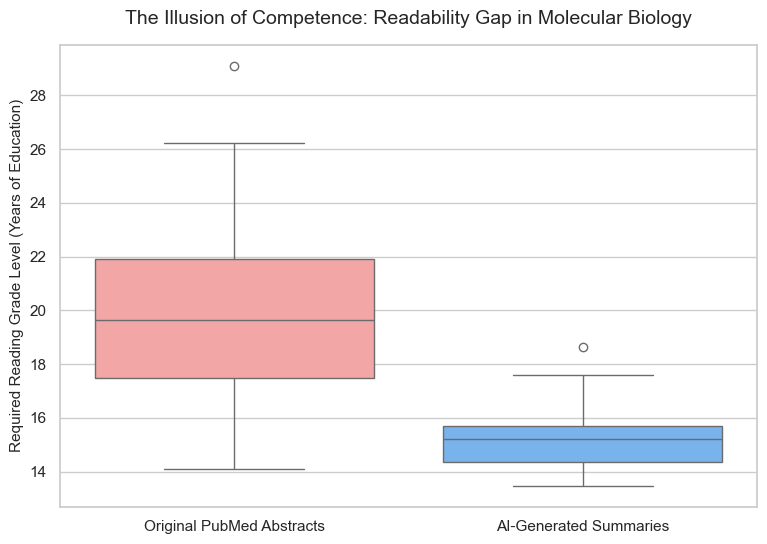

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Save your hard-earned data
df.to_csv('insulin_readability_gap.csv', index=False)
# or use "df = pd.read_csv('insulin_readability_gap.csv')" for shorter method
print("Data saved successfully as 'insulin_readability_gap.csv'")

# 2. Set up the visualization style
plt.figure(figsize=(9, 6))
sns.set_theme(style="whitegrid")

# 3. Reshape the data for plotting
plot_data = pd.melt(df, id_vars=['PMID'], 
                    value_vars=['Original_Grade_Level', 'AI_Grade_Level'],
                    var_name='Text_Type', value_name='Grade_Level')

plot_data['Text_Type'] = plot_data['Text_Type'].replace({
    'Original_Grade_Level': 'Original PubMed Abstracts',
    'AI_Grade_Level': 'AI-Generated Summaries'
})

# 4. Create the box plot
sns.boxplot(x='Text_Type', y='Grade_Level', data=plot_data, palette=['#ff9999', '#66b3ff'])

# 5. Add professional labels
plt.title('The Illusion of Competence: Readability Gap in Molecular Biology', fontsize=14, pad=15)
plt.ylabel('Required Reading Grade Level (Years of Education)', fontsize=11)
plt.xlabel('')

# 6. Display the graph
plt.show()